In [2]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# 创建必要的文件夹（如果你之前已经建好了，这里运行也不会报错）
for p in ['../data/raw', '../data/cleaned', '../data/documentation', '../reports/figures']:
    os.makedirs(p, exist_ok=True)

In [3]:
print("1. 正在读取数据...")
csv_path = '../data/raw/job_data_A2.csv' 
if not os.path.exists(csv_path):
    print(f"找不到 {csv_path}！请确认文件是否在 data/raw 目录下。")
else:
    df = pd.read_csv(csv_path, dtype=str)
    print(f"读取完成，原始形状: {df.shape}")

# 统一列名
expected_cols = ['ID', 'Title', 'Company', 'Industry', 'City', 'Salary min', 'Salary max', 'Salary Period', 'Salary Month', 'Experience', 'Education', 'JD Text', 'Source', 'URL', 'Collecting Date']
if len(df.columns) == len(expected_cols):
    df.columns = expected_cols
    
df.rename(columns={'Collecting Date': 'collection_date'}, inplace=True)

df = df.replace(['NA', 'N/A', 'None', 'none', 'NULL', 'null', ''], np.nan)
df = df.dropna(how='all')
df = df[df['ID'].notna() & df['Title'].notna()].copy()

1. 正在读取数据...
读取完成，原始形状: (234, 15)


In [4]:
print("2. 清洗基础字段...")
df['ID'] = df['ID'].astype(str).str.strip()
df['collector'] = df['ID'].str.extract(r'^([A-Za-z])')
df['record_id'] = df['ID'].str.replace('-', '', regex=False).str.strip()
df['source_platform'] = df['Source'].fillna('BOSS Zhipin')
df['job_title_raw'] = df['Title']
df['job_title_standardized'] = df['Title'].astype(str).str.replace('\n', ' ', regex=False).str.replace('\r', ' ', regex=False).str.strip()
df['company_name'] = df['Company']
df['city'] = df['City']
df['jd_text'] = df['JD Text']
df['url'] = df['URL']
df['collection_date'] = pd.to_datetime(df['collection_date'], errors='coerce')

2. 清洗基础字段...


In [5]:
print("3. 清洗薪资...")
def to_num(x):
    if pd.isna(x): return np.nan
    s = str(x).strip().replace(',', '').replace('元', '').replace('K', '000').replace('k', '000')
    try: return float(s)
    except: return np.nan

def parse_salary(row):
    smin, smax, period = to_num(row['Salary min']), to_num(row['Salary max']), 'month'
    if pd.notna(smin) and pd.notna(smax):
        if smin < 1000 and smax < 1: smax *= 1000; period = 'day'
        elif smin >= 1000 and smax < 100: smax *= 1000
        elif smin < 1000 and smax < 1000: smin *= 1000; smax *= 1000
    return pd.Series([smin, smax, period])

df['salary_raw_min'], df['salary_raw_max'] = df['Salary min'], df['Salary max']
df[['salary_min_clean', 'salary_max_clean', 'salary_period']] = df.apply(parse_salary, axis=1)
df['salary_mid_monthly'] = np.where(df['salary_period'] == 'month', (df['salary_min_clean'] + df['salary_max_clean']) / 2, np.nan)

3. 清洗薪资...


In [7]:
print("4. 清洗经验、学历...")
def clean_experience(x):
    if pd.isna(x): return 'NA'
    s = str(x).lower()
    if 'fresh' in s or 'current student' in s or '应届' in s: return 'Fresh graduate/Student'
    if '<=1' in s or '1年以下' in s: return '<=1 year'
    if '1-3' in s: return '1-3 years'
    if '3-5' in s: return '3-5 years'
    if '5-10' in s: return '5-10 years'
    return 'NA/Other'

def clean_education(x):
    if pd.isna(x): return 'NA'
    s = str(x).lower()
    if 'high school' in s or 'secondary' in s: return 'High school or below'
    if 'junior college' in s or 'diploma in higher vocational' in s: return 'Junior college'
    if 'bachelor' in s: return 'Bachelor'
    if 'master' in s: return 'Master'
    return 'NA/Other'

df['experience_clean'] = df['Experience'].apply(clean_experience)
df['education_clean'] = df['Education'].apply(clean_education)

4. 清洗经验、学历...


In [8]:
print("5. 清洗行业与城市...")
df['industry_clean'] = df['Industry'].astype(str).str.strip().replace({'omputer software': 'Computer software', 'New retail': 'New Retail'})
city_tier_map = {'Beijing': 'Tier 1', 'Shanghai': 'Tier 1', 'Guangzhou': 'Tier 1', 'Shenzhen': 'Tier 1', 'Hangzhou': 'New Tier 1', 'Chengdu': 'New Tier 1', 'Wuhan': 'New Tier 1', 'Nanjing': 'New Tier 1', 'Xiamen': 'Tier 2'}
df['city_tier'] = df['city'].map(city_tier_map).fillna('Other/Unknown')

5. 清洗行业与城市...


In [9]:
print("6. 角色分类、标记并剔除垃圾数据...")
def classify_role(row):
    text = (str(row['Title']) + ' ' + str(row['JD Text'])).lower()
    if any(k in text for k in ['商业分析', 'business analyst', '业务分析', '经营分析']): return 'Business Analyst'
    if any(k in text for k in ['数据科学', 'data science', '数据挖掘']): return 'Data Science'
    if any(k in text for k in ['bi', '商业智能', '报表', '看板', 'power bi', 'tableau']): return 'BI Analyst'
    if any(k in text for k in ['数据运营', '运营分析', 'operation analyst']): return 'Operations Analyst'
    if any(k in text for k in ['数据分析', 'data analyst']): return 'Data Analyst'
    return 'Other/Unclear'

df['role_family'] = df.apply(classify_role, axis=1)

# 初步标记
df['eligible'] = df.apply(lambda r: 0 if (r['role_family'] == 'Other/Unclear' or any(k in str(r['Title']).lower() for k in ['销售', '客服', '合伙人', '活动策划', '招商'])) else 1, axis=1)

# 【新增】：加入黑名单关键词，直接标记为不可用 (0)
bad_keywords = ['小白', '销售', '合伙人', '客服', '兼职', '录入', '同上', '电销', '交易员']
df.loc[df['job_title_raw'].str.contains('|'.join(bad_keywords), na=False, case=False), 'eligible'] = 0

# 【新增】：提取出纯正的“可用池” (只保留 eligible == 1 的)
df_clean_pool = df[df['eligible'] == 1].copy()
print(f"原始数据 {len(df)} 条，剔除垃圾后可用池 {len(df_clean_pool)} 条。")

6. 角色分类、标记并剔除垃圾数据...
原始数据 232 条，剔除垃圾后可用池 194 条。


In [10]:
print("7. 技能关键词标记...")
def flag_kw(text, patterns):
    return int(any(re.search(p, str(text), flags=re.IGNORECASE) for p in patterns))

df['sql_flag'] = df['JD Text'].apply(lambda x: flag_kw(x, [r'\bSQL\b']))
df['python_flag'] = df['JD Text'].apply(lambda x: flag_kw(x, [r'\bPython\b']))
df['excel_flag'] = df['JD Text'].apply(lambda x: flag_kw(x, [r'\bExcel\b']))
df['ai_flag'] = df['JD Text'].apply(lambda x: flag_kw(x, [r'\bAI\b', r'AIGC', r'LLM', r'大模型', r'生成式', r'ChatGPT', r'Agent', r'智能问数', r'A1技术']))

7. 技能关键词标记...


In [11]:
print("8. 导出清洗后数据...")
cleaned_cols = ['record_id', 'collector', 'collection_date', 'source_platform', 'job_title_raw', 'job_title_standardized', 'role_family', 'eligible', 'company_name', 'industry_clean', 'city', 'city_tier', 'salary_raw_min', 'salary_raw_max', 'salary_min_clean', 'salary_max_clean', 'salary_period', 'salary_mid_monthly', 'experience_clean', 'education_clean', 'jd_text', 'url', 'ai_flag', 'sql_flag', 'python_flag', 'excel_flag']
for c in cleaned_cols:
    if c not in df.columns: df[c] = np.nan

# 1. 保存全量数据
cleaned = df[cleaned_cols].copy()
cleaned.to_csv('../data/cleaned/boss_pilot_A2_cleaned.csv', index=False, encoding='utf-8-sig')
df.to_csv('../data/raw/boss_pilot_A2_raw_merged.csv', index=False, encoding='utf-8-sig')

# 2. 从最终的 cleaned 中提取干净池
final_clean_pool = cleaned[cleaned['eligible'] == 1].copy()
final_clean_pool.to_csv('../data/cleaned/clean_pool_for_gold_set.csv', index=False, encoding='utf-8-sig')
print("已导出 clean_pool_for_gold_set.csv 供组员打标！")

8. 导出清洗后数据...
已导出 clean_pool_for_gold_set.csv 供组员打标！


9. 生成图表与黄金样本...


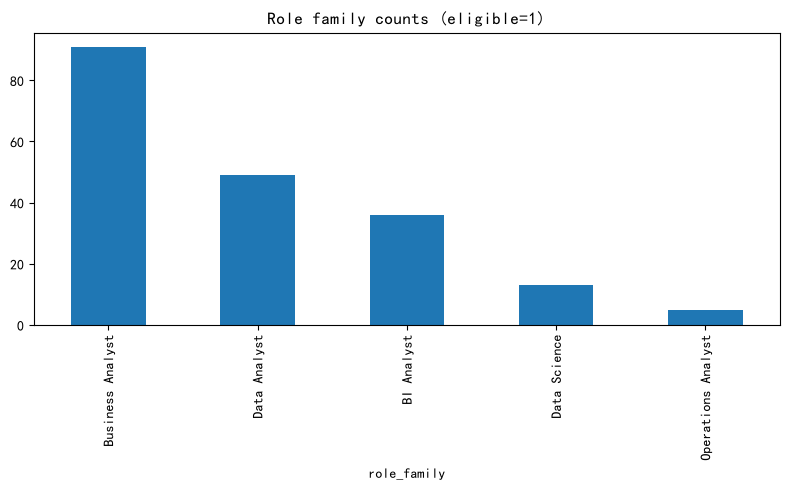

🎉 全部完成！数据已保存在 data/cleaned/ 文件夹中。


In [12]:
print("9. 生成图表与黄金样本...")
# 画图部分
plt.figure(figsize=(8, 5))
cleaned[cleaned['eligible'] == 1]['role_family'].value_counts().plot(kind='bar')
plt.title('Role family counts (eligible=1)')
plt.tight_layout()
plt.savefig('../reports/figures/role_family_counts_A2.png', dpi=200) # 保存路径加了 ../
plt.show() # 让图在 Notebook 里显示出来

# 抽样提取黄金样本
gold_sample = final_clean_pool.sample(n=min(150, len(final_clean_pool)), random_state=42).copy()
gold_sample['gold_role_family'] = ''
gold_sample['gold_ai_flag'] = ''
gold_sample['gold_notes'] = ''
gold_sample.to_csv('../data/documentation/gold_set_to_code_A2.csv', index=False, encoding='utf-8-sig')

print("🎉 全部完成！数据已保存在 data/cleaned/ 文件夹中。")